# Intel Order book : predicting the mid-price 10s ahead 

Trying to take a limit-order book for Intel, cleaning it up, and then building a set of features to use to predict whether the mid-price will move up or down using logistic regression.

Data: Nasdaq TotalView-ITCH for 30 Dec 2019, rebuilt into a 10-level book (thanks Claude)

Units:  Time is nanoseconds since midnight, US Eastern. 
        Prices are integers in $0.0001, so 596300 is $59.63
        Sizes are shares

## 1. Setup

In [1]:
import pandas as pd
import numpy as np

TICKER = 'INTC'

OPEN = pd.Timedelta('09:30:00').value
CLOSE = pd.Timedelta('16:00:00').value
STEP = pd.Timedelta('1s').value             #spacing of the resampled book

## 2. Load the data

The msg stream is not uniform, events arrive at random times one after another. The book does not have timestamps, row i of the 'book' is the state straight after event i in 'msg'. 

### Data key

**`msg`**: one row per order book event.

| Column     | Meaning                                                                                                    |
| ---------- | ---------------------------------------------------------------------------------------------------------- |
| `time`     | Nanoseconds since midnight, US Eastern                                                                     |
| `event`    | `add`, `cancel` (part of an order), `delete` (whole order), `execute`, `hidden_execute`, `cross` (auction) |
| `order_id` | Exchange order reference                                                                                   |
| `side`     | +1 buy order, -1 sell order, 0 not reported. On an `execute` it is the resting order's side                |
| `price`    | Price of the order affected, in $0.0001                                                                    |
| `size`     | Shares added, removed or traded                                                                            |
| `itch`     | See below                                                                                                  |

**`itch` **: the raw Nasdaq message each row came from, and the `event` it became.

| `itch` | Nasdaq message                                        | `event`                      |
| ------ | ----------------------------------------------------- | ---------------------------- |
| A      | Add order                                             | `add`                        |
| F      | Add order, naming the firm that placed it             | `add`                        |
| X      | Cancel part of an order                               | `cancel`                     |
| D      | Delete a whole order                                  | `delete`                     |
| E      | Order executed at its own price                       | `execute`                    |
| C      | Order executed at a different price (mostly auctions) | `execute`                    |
| U      | Replace an order with a new one                       | `delete` row, then `add` row |
| P      | Trade against a hidden order                          | `hidden_execute`             |
| Q      | Opening or closing auction trade                      | `cross`                      |

**`book`**: the book straight after each event, 10 levels per side.

| Column                       | Meaning                                                  |
| ---------------------------- | -------------------------------------------------------- |
| `ask_price_k`, `bid_price_k` | Price at level k, in \$0.0001. Level 1 is the best price |
| `ask_size_k`, `bid_size_k`   | Total shares resting at that level                       |

In [2]:
msg = pd.read_parquet("data/INTC_2019-12-30_messages.parquet")
book = pd.read_parquet("data/INTC_2019-12-30_book.parquet")
assert len(msg) == len(book)

book['time'] = msg['time']

book.shape

(792985, 41)

In [3]:
msg.head()

,time,event,order_id,side,price,size,itch
0,14742473605633,add,118530,1,602500,200,A
1,14742499707646,delete,118530,1,602500,200,D
2,16503897501343,add,324054,1,600800,3,A
3,22821696579852,delete,324054,1,600800,3,D
4,24161597257912,add,1227342,1,589400,1000,A


## 3. Resample the LOB to a regular grid of time

We want to have the book at uniform points in time, the events stream (msg level stream) is not uniform and can have bursts of liquidity. 

In [4]:
grid = pd.DataFrame({'time': np.arange(OPEN, CLOSE, STEP)})
book_grid = pd.merge_asof(grid, book, on = 'time')

assert len(book_grid) == (CLOSE - OPEN) // STEP
assert book_grid.notna().all().all()
assert (book_grid['ask_price_1'] > book_grid['bid_price_1']).all()

book_grid[['time', 'bid_price_1', 'bid_size_1', 'ask_price_1', 'ask_size_1']].head()


,time,bid_price_1,bid_size_1,ask_price_1,ask_size_1
0,34200000000000,599700.0,100,600900.0,200
1,34201000000000,599600.0,4000,600800.0,11
2,34202000000000,600000.0,1127,600400.0,300
3,34203000000000,600000.0,1215,600500.0,801
4,34204000000000,600100.0,200,600500.0,633


## 4. Features

Create a new dataframe for the features that we will use to ultimately make our predictions. 
Features may only use information looking at it's own rows or earlier.

Features are simple and intuitive like the weighted-mid, spread... as well as some inspired by this blog by Headlands technologies (impulse etc) https://blog.headlandstech.com/2017/08/03/quantitative-trading-summary/

In [5]:
DEPTH = 10

bid = book_grid['bid_price_1']
ask = book_grid['ask_price_1']
bid_size = book_grid['bid_size_1']
ask_size = book_grid['ask_size_1']

mid = (bid + ask) / 2
spread = ask - bid
wmid = (bid * ask_size + ask * bid_size) / (bid_size + ask_size)

bid_depth = book_grid[[f'bid_size_{k}' for k in range(1, DEPTH + 1)]].sum(axis = 1)
ask_depth = book_grid[[f'ask_size_{k}' for k in range(1, DEPTH + 1)]].sum(axis = 1)

assert ((mid > bid) & (mid < ask)).all()

#Features

features = pd.DataFrame(index = book_grid.index)

features['spread'] = spread 
features['imbalance'] = (bid_size - ask_size) / (bid_size + ask_size)
features['wmid_gap'] = wmid - mid
features['depth_imbalance'] = (bid_depth - ask_depth) / (bid_depth + ask_depth)
features['ret_5s'] = mid.diff(5) 
features['ret_10s'] = mid.diff(10)
features['imbalance_trend'] = features['imbalance'] - features['imbalance'].rolling(10).mean()

features.dropna().head()

,spread,imbalance,wmid_gap,depth_imbalance,ret_5s,ret_10s,imbalance_trend
10,400.0,-0.052133,-10.426540,-0.114020,50.0,0.0,-0.274521
11,400.0,-0.052133,-10.426540,-0.114020,50.0,100.0,-0.169856
12,400.0,-0.052133,-10.426540,-0.122336,0.0,100.0,-0.106689
13,400.0,-0.052133,-10.426540,-0.122336,0.0,50.0,-0.080940
14,300.0,0.234568,35.185185,-0.081451,-50.0,-50.0,0.130323


## 5. Labelling the data

We are predicting the direction of the mid price over the next T seconds (10 in the base case)

+1 = up

0 = unchanged

-1 = down

In [6]:
HORIZON = 10                                    # Time horizon for the prediction      

change = mid.shift(-HORIZON) - mid              # Mid 10s from now minus the current mid
direction = np.sign(change)                     # +1 up, 0 flat, -1 down

direction.value_counts(dropna = False)          # Count of each direction (NaN for end of trading day)  

 0.0    14083
 1.0     4710
-1.0     4597
 NaN       10
Name: count, dtype: int64

## 6. Cleaning the data and splitting it into train and test sets

For the simple two way classification model, we only want to keep the seconds that have every feature and the mid moved. Then split by time, train on everything before 14:00 and test on everything after (up until 16:00))

In [7]:
SPLIT = pd.Timedelta('14:00:00').value          # Train before this time, test after

keep = features.notna().all(axis = 1) & direction.notna() & (direction !=0)

X = features[keep]
y = (direction[keep] > 0).astype(float)         # 1 up, 0 down
time = book_grid['time'][keep]


train = time < SPLIT - HORIZON * STEP           # Stop short of the split to avoid lookahead bias
test = time >= SPLIT


assert not (train & test).any()                 # No overlap between train and test
print(f'{len(X):,} rows kept: {train.sum():,} train, {test.sum():,} test')
print(f'up share: {y[train].mean():.3f} train, {y[test].mean():.3f} test') 

9,298 rows kept: 7,132 train, 2,166 test
up share: 0.510 train, 0.492 test


## 7. Standardise the features

Standardise every feature (to mean = 0, standard deviation = 1) so that gradient descent treats them equally

In [14]:
mean = X[train].mean()
std = X[train].std()

X_train = (X[train] - mean) / std
X_test = (X[test] - mean) / std

y_train = y[train]
y_test = y[test]

X_train.describe().loc[['mean', 'std']].round(2)

,spread,imbalance,wmid_gap,depth_imbalance,ret_5s,ret_10s,imbalance_trend
mean,0.0,0.0,-0.0,-0.0,-0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## 8. Model

Logistic regression from first principles (without using scikit-learn)

### 1. Linear Combination

For each observation, calculate the weighted sum of the input features:

$$
z_i = \sum_{j=1}^{p} w_j x_{ij} + b
$$

where $w_j$ are the model weights and $b$ is the bias.

### 2. Sigmoid Prediction

Pass the linear combination through the sigmoid function to obtain the predicted probability:

$$
\hat{y}_i = \sigma(z_i) = \frac{1}{1 + e^{-z_i}}
$$

where:

$$
0 < \hat{y}_i < 1
$$

### 3. Binary Cross-Entropy Loss

Measure the error between the true labels $y_i$ and predictions $\hat{y}_i$:

$$
\mathcal{L}
=
-\frac{1}{N}
\sum_{i=1}^{N}
\left[
y_i \log(\hat{y}_i)
+
(1-y_i)\log(1-\hat{y}_i)
\right]
$$

### 4. Calculate Gradients

Compute the gradient of the loss with respect to each weight and the bias:

$$
\frac{\partial \mathcal{L}}{\partial w_j}
=
\frac{1}{N}
\sum_{i=1}^{N}
(\hat{y}_i-y_i)x_{ij}
$$

$$
\frac{\partial \mathcal{L}}{\partial b}
=
\frac{1}{N}
\sum_{i=1}^{N}
(\hat{y}_i-y_i)
$$

### 5. Gradient Descent

Update the parameters using learning rate $\eta$:

$$
w_j
\leftarrow
w_j-\eta\frac{\partial\mathcal{L}}{\partial w_j}
$$

$$
b
\leftarrow
b-\eta\frac{\partial\mathcal{L}}{\partial b}
$$

Repeat the prediction, loss, gradient, and update steps for a fixed number of iterations.

### 6. Classification

Convert the predicted probability into a class using a threshold of $0.5$:

$$
\hat{c}_i =
\begin{cases}
1 & \text{if } \hat{y}_i > 0.5 \\
0 & \text{if } \hat{y}_i \leq 0.5
\end{cases}
$$

In [15]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))


def predict(X, w, b):
    return sigmoid(X @ w + b)                                       # Probability of up move for each row in X

def loss(p, y):
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))        # Binary cross-entropy loss


def gradient(X, p, y):
    
    error = p - y

    return X.T @ error / len(X), error.mean()                      # Gradient of the loss with respect to w and b


def accuracy(p, y):
    return np.mean((p>0.5) == (y == 1))

## 9. Training the model

Predict > measure the slope of the loss for each weight > move each weight a small step downhill

Text(0, 0.5, 'training loss')

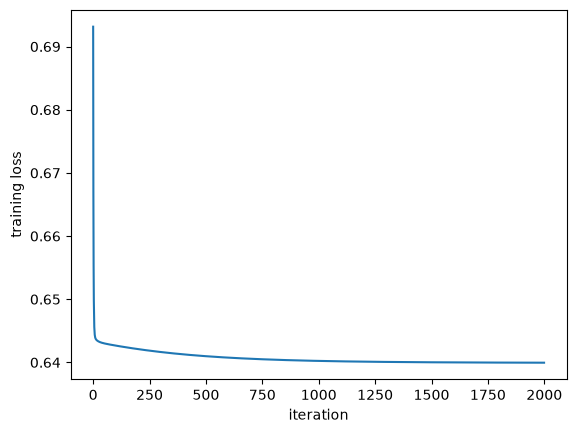

In [16]:
import matplotlib.pyplot as plt

ITERATIONS = 2000
LEARNING_RATE = 0.5

Xtr, ytr = X_train.to_numpy(), y_train.to_numpy()
Xte, yte = X_test.to_numpy(), y_test.to_numpy()

w = np.zeros(Xtr.shape[1])                          # One weight per feature, initialised to zero
b = 0.0
history = []


for i in range(ITERATIONS):
    p = predict(Xtr, w, b)                           # Predicted probability of up move for each row in Xtr
    history.append(loss(p, ytr))                     # Loss for the current weights and bias
    
    grad_w, grad_b = gradient(Xtr, p, ytr)

    w -= LEARNING_RATE * grad_w
    b -= LEARNING_RATE * grad_b


plt.plot(history)
plt.xlabel('iteration')
plt.ylabel('training loss')


## 10. Evaluate

Test the model on the afternoon test set.

In [17]:
p_train = predict(Xtr, w, b)
p_test = predict(Xte, w, b)

print(f'train: loss {loss(p_train, ytr):.4f}, accuracy {accuracy(p_train, ytr):.3f}')
print(f'test:  loss {loss(p_test, yte):.4f}, accuracy {accuracy(p_test, yte):.3f}')

train: loss 0.6400, accuracy 0.638
test:  loss 0.5943, accuracy 0.711
